# 01. 뉴스 요약 데이터 탐색(EDA)

이 노트북은 모델 학습 전에 데이터의 상태를 숫자와 그래프로 확인합니다.

- 제공된 train / validation / test 분할은 그대로 유지합니다.
- 결측치, 빈 문자열, 길이, 중복, 요약 노이즈 후보를 확인합니다.
- KoBART 토큰 길이를 측정해 입력 길이 512와 1024 비교 실험의 근거를 만듭니다.
- 이 단계에서는 데이터를 삭제하거나 모델을 학습하지 않습니다.
- test는 분할 구조와 입력 분포·중복 여부만 확인하며, test 정답을 보고 설정을 선택하지 않습니다.

커널: **Python 3.11 (Team4 News GPU)**

## 1. 프로젝트 경로와 라이브러리

프로젝트 가상환경을 사용 중인지 확인하고 결과 폴더를 준비합니다.

In [2]:
import os
import sys
from pathlib import Path

PROJECT = Path("C:/Users/KDS-30/Desktop/Projects/06_Team_Project4")
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

RESULTS = PROJECT / "results" / "01_data_eda"
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("실행 파일:", sys.executable)
print("결과 폴더:", RESULTS)

Python: 3.11.9
실행 파일: c:\Users\KDS-30\Desktop\Projects\06_Team_Project4\.venv\Scripts\python.exe
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda


In [3]:
import hashlib
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import AutoTokenizer

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_ID = "gogamza/kobart-base-v2"

## 2. 원본 데이터 불러오기

Hugging Face에 저장된 원본 버전을 기록하고 세 분할을 DataFrame으로 변환합니다. `split` 컬럼은 각 행이 어느 분할에서 왔는지 표시합니다.

In [4]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revision = api.model_info(MODEL_ID).sha

ds = load_dataset(DATASET_ID, revision=dataset_revision)
frames = {}
for split, dataset in ds.items():
    frame = dataset.to_pandas()
    frame["split"] = split
    frames[split] = frame

all_df = pd.concat(frames.values(), ignore_index=True)
split_order = ["train", "validation", "test"]

print("데이터 버전:", dataset_revision)
print("모델 버전:", model_revision)
display(pd.DataFrame({
    "split": split_order,
    "건수": [len(frames[s]) for s in split_order],
    "비율(%)": [len(frames[s]) / len(all_df) * 100 for s in split_order],
}).round(2))
print("전체:", f"{len(all_df):,}건")
print("컬럼:", list(ds["train"].column_names))

데이터 버전: 916dfe6aed651b2ecd9d04fa0a704f8953e90762
모델 버전: f5899cc556216353e23ee36b66fad52b902066c5


,split,건수,비율(%)
0,train,22194,81.0
1,validation,2466,9.0
2,test,2740,10.0


전체: 27,400건
컬럼: ['date', 'category', 'press', 'title', 'document', 'link', 'summary']


## 3. 컬럼 형태와 실제 한 건 확인

각 컬럼의 자료형과 첫 번째 train 기사 한 건을 확인합니다. `document`가 입력이고 `summary`가 학습 정답입니다.

In [5]:
display(frames["train"].dtypes.rename("dtype").to_frame())
example_columns = ["date", "category", "press", "title", "document", "summary", "link"]
display(frames["train"].loc[[0], example_columns].T.rename(columns={0: "train[0]"}))

,dtype
date,object
category,object
press,object
title,object
document,object
link,object
summary,object
split,object


,train[0]
date,2022-07-03 17:14:37
category,economy
press,YTN
title,추경호 중기 수출지원 총력 무역금융 40조 확대
document,앵커 정부가 올해 하반기 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 했습니다. 특히 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대하...
summary,"올해 상반기 우리나라 무역수지는 역대 최악인 103억 달러 적자를 기록한 가운데, 정부가 하반기에 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 결정한 가운데, ..."
link,https://n.news.naver.com/mnews/article/052/0001759333?sid=101


## 4. 결측치와 빈 문자열

결측치는 값 자체가 없는 경우이고, 빈 문자열은 문자열은 있지만 공백을 제거하면 내용이 없는 경우입니다.

In [6]:
text_columns = ["date", "category", "press", "title", "document", "link", "summary"]
quality_rows = []
for split in split_order:
    frame = frames[split]
    for column in text_columns:
        quality_rows.append({
            "split": split,
            "column": column,
            "missing": int(frame[column].isna().sum()),
            "empty": int(frame[column].fillna("").astype(str).str.strip().eq("").sum()),
        })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)
print("전체 결측치:", int(quality_df["missing"].sum()))
print("전체 빈 문자열:", int(quality_df["empty"].sum()))

,split,column,missing,empty
0,train,date,0,0
1,train,category,0,0
2,train,press,0,0
3,train,title,0,0
4,train,document,0,0
5,train,link,0,0
6,train,summary,0,0
7,validation,date,0,0
8,validation,category,0,0
9,validation,press,0,0


전체 결측치: 0
전체 빈 문자열: 0


## 5. 날짜·분야·언론사 분포

세 분할에 같은 날짜 범위와 비슷한 분야 비율이 들어 있는지 확인합니다.

In [7]:
for frame in frames.values():
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
all_df = pd.concat(frames.values(), ignore_index=True)

split_profile = []
for split in split_order:
    frame = frames[split]
    split_profile.append({
        "split": split,
        "건수": len(frame),
        "시작일": frame["date"].min(),
        "종료일": frame["date"].max(),
        "언론사 수": frame["press"].nunique(),
        "경제 비율(%)": frame["category"].eq("economy").mean() * 100,
        "IT과학 비율(%)": frame["category"].eq("IT과학").mean() * 100,
    })
split_profile_df = pd.DataFrame(split_profile)
display(split_profile_df.round(2))

category_table = pd.crosstab(all_df["split"], all_df["category"]).reindex(split_order)
display(category_table)

,split,건수,시작일,종료일,언론사 수,경제 비율(%),IT과학 비율(%)
0,train,22194,2022-07-01 00:01:01,2022-07-10 23:11:01,79,76.99,23.01
1,validation,2466,2022-07-01 00:00:00,2022-07-10 21:25:44,74,75.95,24.05
2,test,2740,2022-07-01 00:01:08,2022-07-10 21:08:01,72,76.20,23.80


category,IT과학,economy
split,,
train,5106,17088
validation,593,1873
test,652,2088


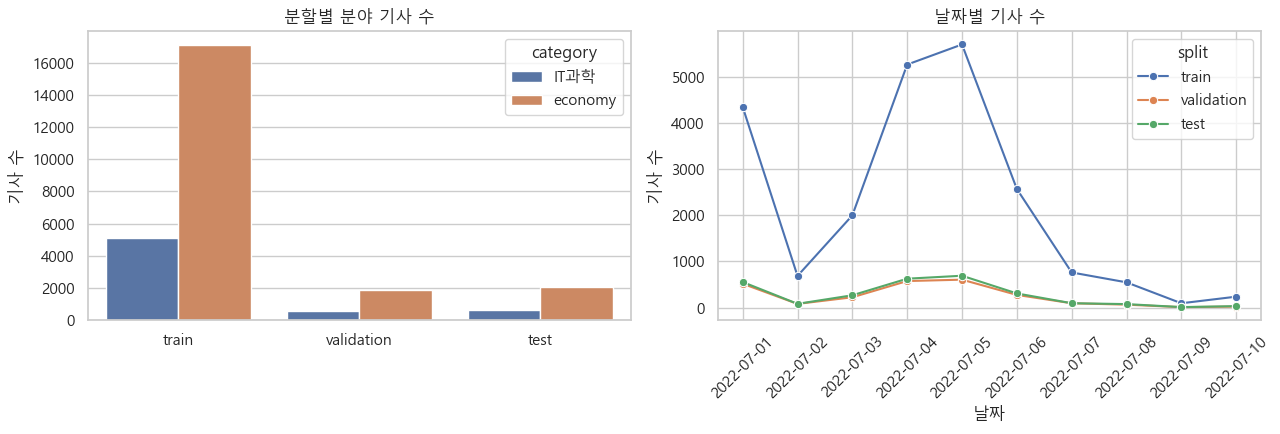

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

category_plot = (
    all_df.groupby(["split", "category"], observed=True)
    .size().rename("count").reset_index()
)
sns.barplot(data=category_plot, x="split", y="count", hue="category",
            order=split_order, ax=axes[0])
axes[0].set_title("분할별 분야 기사 수")
axes[0].set_xlabel("")
axes[0].set_ylabel("기사 수")

date_plot = (
    all_df.assign(day=all_df["date"].dt.date)
    .groupby(["day", "split"], observed=True)
    .size().rename("count").reset_index()
)
sns.lineplot(data=date_plot, x="day", y="count", hue="split",
             hue_order=split_order, marker="o", ax=axes[1])
axes[1].set_title("날짜별 기사 수")
axes[1].set_xlabel("날짜")
axes[1].set_ylabel("기사 수")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(FIGURES / "01_category_date_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. 글자·어절 길이

- 글자 수: Python의 `len()`으로 센 문자 개수
- 어절 수: 공백으로 나눈 덩어리 수
- 압축 비율: 요약 글자 수 ÷ 본문 글자 수

토큰 수와는 다른 값이며, 먼저 데이터의 대략적인 길이와 극단값을 확인하는 용도입니다.

In [9]:
for frame in frames.values():
    frame["document_chars"] = frame["document"].fillna("").str.len()
    frame["summary_chars"] = frame["summary"].fillna("").str.len()
    frame["document_words"] = frame["document"].fillna("").str.split().str.len()
    frame["summary_words"] = frame["summary"].fillna("").str.split().str.len()
    frame["char_compression_ratio"] = (
        frame["summary_chars"] / frame["document_chars"].replace(0, np.nan)
    )

all_df = pd.concat(frames.values(), ignore_index=True)
length_columns = [
    "document_chars", "summary_chars",
    "document_words", "summary_words", "char_compression_ratio"
]
length_summary = (
    all_df.groupby("split")[length_columns]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
)
display(length_summary.round(2))

document_chars                                                \
                    count    mean     std   min     25%    50%      75%   
split                                                                     
test               2740.0   995.7  762.79  49.0  508.00  861.0  1257.25   
train             22194.0   998.6  798.01  29.0  517.00  854.0  1286.75   
validation         2466.0  1016.1  831.85  48.0  515.25  864.5  1302.75   

                                              summary_chars                 \
               90%      95%      99%      max         count    mean    std   
split                                                                        
test        1864.1  2344.05  3728.81   9221.0        2740.0  184.16  91.31   
train       1857.7  2306.35  3734.35  16889.0       22194.0  183.22  81.57   
validation  1867.5  2326.75  3916.75  15384.0        2466.0  180.92  75.62   

                  ... summary_words                      \
             min  ...           90%   95%    99%    max   
split             ...                                     
test        66.0  ...          58.0  67.0  105.0  464.0   
train       59.0  ...          58.0  66.0   99.0  484.0   
validation  60.0  ...          57.0  64.0   96.0  484.0   

           char_compression_ratio                                            \
                            count  mean   std   min   25%   50%   75%   90%   
split                                                                         
test                       2740.0  0.42  1.08  0.02  0.13  0.20  0.35  0.79   
train                     22194.0  0.43  1.10  0.01  0.13  0.21  0.35  0.81   
validation                 2466.0  0.40  0.87  0.01  0.13  0.20  0.34  0.84   

                               
             95%   99%    max  
split                          
test        1.30  2.88  29.17  
train       1.43  3.26  39.00  
validation  1.43  2.66  26.44  

[3 rows x 55 columns]

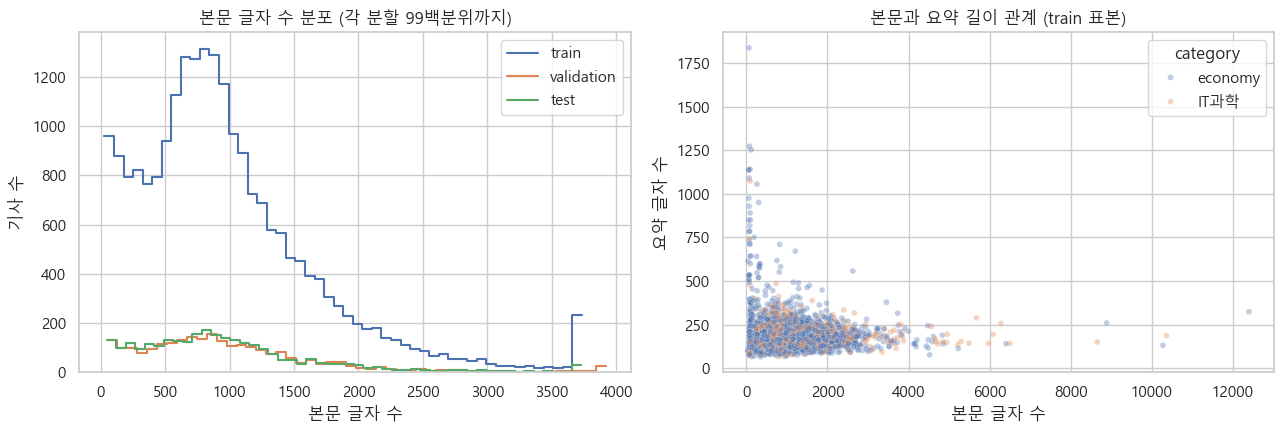

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for split in split_order:
    values = frames[split]["document_chars"].clip(upper=frames[split]["document_chars"].quantile(0.99))
    sns.histplot(values, bins=50, element="step", fill=False, label=split, ax=axes[0])
axes[0].set_title("본문 글자 수 분포 (각 분할 99백분위까지)")
axes[0].set_xlabel("본문 글자 수")
axes[0].set_ylabel("기사 수")
axes[0].legend()

sample_for_scatter = frames["train"].sample(
    min(5000, len(frames["train"])), random_state=SEED
)
sns.scatterplot(
    data=sample_for_scatter, x="document_chars", y="summary_chars",
    hue="category", alpha=0.35, s=18, ax=axes[1]
)
axes[1].set_title("본문과 요약 길이 관계 (train 표본)")
axes[1].set_xlabel("본문 글자 수")
axes[1].set_ylabel("요약 글자 수")

plt.tight_layout()
plt.savefig(FIGURES / "02_character_length_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. KoBART 토큰 길이

실제 KoBART 토크나이저로 모든 본문과 요약의 토큰 수를 셉니다. 여기서는 길이를 측정할 뿐 자르지 않습니다. 512·1024토큰 초과 비율은 이후 입력 길이 실험의 근거가 됩니다.

In [11]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=model_revision, clean_up_tokenization_spaces=False
)

def token_lengths(texts, batch_size=512):
    lengths = []
    texts = texts.fillna("").astype(str).tolist()
    for start in range(0, len(texts), batch_size):
        encoded = tokenizer(
            texts[start:start + batch_size],
            add_special_tokens=True,
            truncation=False,
            return_attention_mask=False,
            return_token_type_ids=False,
            return_length=True,
            verbose=False,
        )
        lengths.extend(encoded["length"])
    return lengths

for split in split_order:
    frame = frames[split]
    frame["document_tokens"] = token_lengths(frame["document"])
    frame["summary_tokens"] = token_lengths(frame["summary"])

all_df = pd.concat(frames.values(), ignore_index=True)
token_stats = []
for split in split_order:
    frame = frames[split]
    token_stats.append({
        "split": split,
        "본문 토큰 중앙값": frame["document_tokens"].median(),
        "본문 토큰 90%": frame["document_tokens"].quantile(0.90),
        "본문 토큰 95%": frame["document_tokens"].quantile(0.95),
        "본문 토큰 99%": frame["document_tokens"].quantile(0.99),
        "본문 최대": frame["document_tokens"].max(),
        "512 초과(건)": frame["document_tokens"].gt(512).sum(),
        "512 초과(%)": frame["document_tokens"].gt(512).mean() * 100,
        "1024 초과(건)": frame["document_tokens"].gt(1024).sum(),
        "1024 초과(%)": frame["document_tokens"].gt(1024).mean() * 100,
        "요약 토큰 중앙값": frame["summary_tokens"].median(),
        "요약 토큰 99%": frame["summary_tokens"].quantile(0.99),
        "요약 최대": frame["summary_tokens"].max(),
    })
token_stats_df = pd.DataFrame(token_stats)
display(token_stats_df.round(2))

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


,split,본문 토큰 중앙값,본문 토큰 90%,본문 토큰 95%,본문 토큰 99%,본문 최대,512 초과(건),512 초과(%),1024 초과(건),1024 초과(%),요약 토큰 중앙값,요약 토큰 99%,요약 최대
0,train,357.0,776.0,970.00,1548.28,6781,6108,27.52,918,4.14,72.0,213.07,510
1,validation,364.5,777.0,975.25,1630.25,6511,718,29.12,102,4.14,71.0,192.35,509
2,test,361.0,771.1,974.20,1578.98,4445,725,26.46,124,4.53,72.0,249.22,509


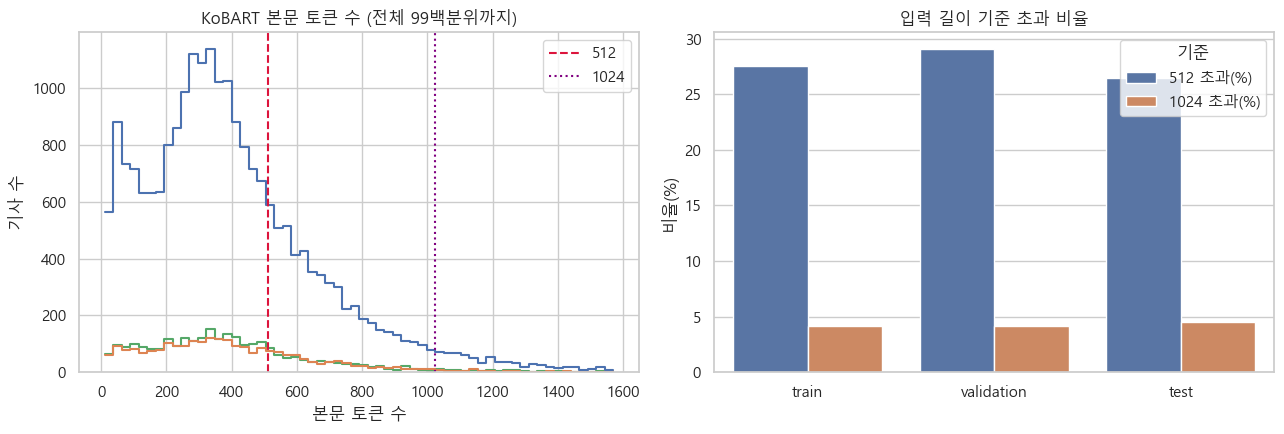

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_tokens = all_df.loc[all_df["document_tokens"] <= all_df["document_tokens"].quantile(0.99)]
sns.histplot(
    data=plot_tokens, x="document_tokens", hue="split",
    hue_order=split_order, bins=60, element="step", fill=False, ax=axes[0]
)
axes[0].axvline(512, color="crimson", linestyle="--", label="512")
axes[0].axvline(1024, color="purple", linestyle=":", label="1024")
axes[0].set_title("KoBART 본문 토큰 수 (전체 99백분위까지)")
axes[0].set_xlabel("본문 토큰 수")
axes[0].set_ylabel("기사 수")
axes[0].legend()

threshold_plot = token_stats_df.melt(
    id_vars="split",
    value_vars=["512 초과(%)", "1024 초과(%)"],
    var_name="기준", value_name="비율"
)
sns.barplot(data=threshold_plot, x="split", y="비율", hue="기준",
            order=split_order, ax=axes[1])
axes[1].set_title("입력 길이 기준 초과 비율")
axes[1].set_xlabel("")
axes[1].set_ylabel("비율(%)")

plt.tight_layout()
plt.savefig(FIGURES / "03_kobart_token_length.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. 각 분할 내부의 정확히 동일한 값

동일 링크·제목·본문·요약이 한 분할 안에 몇 행 있는지 셉니다. `duplicated(keep=False)`는 중복 묶음에 속한 모든 행을 표시합니다.

In [13]:
duplicate_rows = []
for split in split_order:
    frame = frames[split]
    for column in ["link", "title", "document", "summary"]:
        duplicate_rows.append({
            "split": split,
            "기준": column,
            "중복 묶음에 속한 행": int(frame[column].duplicated(keep=False).sum()),
            "첫 행 제외 중복 행": int(frame[column].duplicated(keep="first").sum()),
        })
within_duplicate_df = pd.DataFrame(duplicate_rows)
display(within_duplicate_df)

,split,기준,중복 묶음에 속한 행,첫 행 제외 중복 행
0,train,link,0,0
1,train,title,3082,1815
2,train,document,2834,1907
3,train,summary,2856,1927
4,validation,link,0,0
5,validation,title,68,35
6,validation,document,108,62
7,validation,summary,112,64
8,test,link,0,0
9,test,title,74,37


## 9. 분할 사이의 정확한 중복

같은 내용이 train과 validation/test에 동시에 있으면 모델이 이미 본 기사를 평가받을 수 있습니다. 링크 중복과 내용 중복을 따로 확인합니다. 여기서는 발견만 하고 제거하지 않습니다.

In [14]:
cross_rows = []
for i, left in enumerate(split_order):
    for right in split_order[i + 1:]:
        for column in ["link", "title", "document", "summary"]:
            overlap = set(frames[left][column]) & set(frames[right][column])
            cross_rows.append({
                "left": left,
                "right": right,
                "기준": column,
                "공통 고유값 수": len(overlap),
            })
cross_duplicate_df = pd.DataFrame(cross_rows)
display(cross_duplicate_df.pivot(
    index=["left", "right"], columns="기준", values="공통 고유값 수"
).reset_index())

기준,left,right,document,link,summary,title
0,train,test,274,0,273,331
1,train,validation,259,0,259,332
2,validation,test,79,0,78,78


In [15]:
cross_document_examples = []
for i, left in enumerate(split_order):
    for right in split_order[i + 1:]:
        left_frame = frames[left]
        right_frame = frames[right]
        common_documents = set(left_frame["document"]) & set(right_frame["document"])
        for document in common_documents:
            lrow = left_frame.loc[left_frame["document"].eq(document)].iloc[0]
            rrow = right_frame.loc[right_frame["document"].eq(document)].iloc[0]
            cross_document_examples.append({
                "left": left,
                "right": right,
                "document_sha256": hashlib.sha256(document.encode("utf-8")).hexdigest(),
                "left_title": lrow["title"],
                "right_title": rrow["title"],
                "left_link": lrow["link"],
                "right_link": rrow["link"],
                "document_chars": len(document),
            })

cross_document_examples_df = pd.DataFrame(cross_document_examples)
print("분할 사이 동일 본문 사례:", f"{len(cross_document_examples_df):,}건")
display(cross_document_examples_df.head(10))

분할 사이 동일 본문 사례: 612건


,left,right,document_sha256,left_title,right_title,left_link,right_link,document_chars
0,train,validation,0bd7c2ce068c359456073117adf672f0cd506e0800271081d47d3ba119e2542c,셀시우스·3AC·볼드 등 비트코인 폭락으로 파산업체 속출종합,셀시우스·3AC·볼드 등 비트코인 폭락으로 파산업체 속출종합,https://n.news.naver.com/mnews/article/421/0006196951?sid=101,https://n.news.naver.com/mnews/article/421/0006196951?sid=105,1630
1,train,validation,fc0af5de033766481e1a5fb119cdcfd610e7fefa8fd547eb3e52ae91fd50e560,원안위 원자력 규제 현안 점검단 구성,원안위 원자력 규제 현안 논의 위해 점검단 구성,https://n.news.naver.com/mnews/article/001/0013290417?sid=101,https://n.news.naver.com/mnews/article/001/0013290469?sid=101,192
2,train,validation,52e80fec6b29fc3d7b766b1aeb876502e6dc0c0983b438577c102fb127d533de,구글 카카오톡 업데이트 중단…애플도 ‘꼼수’,구글 카카오톡 업데이트 중단…애플도 ‘꼼수’,https://n.news.naver.com/mnews/article/056/0011296929?sid=105,https://n.news.naver.com/mnews/article/056/0011296462?sid=105,909
3,train,validation,6daa1da7c74b2cac91c3c04af704c8f8b148555bf1255e5ccb1c886e160beb8d,네이버 지도 목적지 검색하면 기차 예매까지 한번에,네이버 지도 목적지 검색하면 기차 예매까지 한번에,https://n.news.naver.com/mnews/article/018/0005259082?sid=101,https://n.news.naver.com/mnews/article/018/0005259082?sid=105,1075
4,train,validation,6e6aabeef0d542c6754a97ceb877cf23a71228e6734b7db4c0f119f50405053a,전력 유관기관별 상황점검회의,전력 유관기관별 상황점검회의 나선 박일준 차관,https://n.news.naver.com/mnews/article/421/0006195178?sid=101,https://n.news.naver.com/mnews/article/421/0006195180?sid=101,87
5,train,validation,23aa26d81a1a3204c2af7a286c2659dfa0dbf84a86998c4a51cb9dd072d13248,구글 인앱결제 본보기 된 카톡…조승래 방통위 실태점검 핑계만,구글 인앱결제 본보기 된 카톡…조승래 방통위 실태점검 핑계만,https://n.news.naver.com/mnews/article/003/0011287168?sid=101,https://n.news.naver.com/mnews/article/003/0011287168?sid=105,1436
6,train,validation,4e415c240e7251a70a61e79ad82a6ee326e61315c84529debf4ff19f833a9d67,애플 엔화 약세 日서 아이폰값 올려…18만원 더 비싸졌다,애플 엔화 약세 日서 아이폰값 올려…18만원 더 비싸졌다,https://n.news.naver.com/mnews/article/421/0006191433?sid=105,https://n.news.naver.com/mnews/article/421/0006191433?sid=101,623
7,train,validation,c8a72680268e98cc1c744f1e266ff5c4349d4cefa29e0d1bab367e12830be3bc,성북구 러브버그 대응 방역기 시연,성북구 러브버그 대응 방역기 시연,https://n.news.naver.com/mnews/article/421/0006197695?sid=101,https://n.news.naver.com/mnews/article/421/0006197703?sid=101,319
8,train,validation,ecd0381abd3015c3b38990ee04eb003eb5d2748bb4e12b583f1267ac722d0c94,코스피 2300.34 마감 장중 2300선 붕괴되기도...,코스피 2300.34 마감 장중 2300선 붕괴되기도...,https://n.news.naver.com/mnews/article/003/0011284471?sid=101,https://n.news.naver.com/mnews/article/003/0011284472?sid=101,377
9,train,validation,02b3eb5a3bb1fddda8e3b85a24e9e88c8000c19c50b647450bc4a43e2dc94746,장중 2300 무너진 코스피,장중 2300선 밑으로 내려간 코스피,https://n.news.naver.com/mnews/article/003/0011282833?sid=101,https://n.news.naver.com/mnews/article/003/0011282850?sid=101,394


## 10. train 정답 요약의 노이즈 후보 탐지

자동 규칙은 오류를 확정하지 않고 사람이 읽을 후보를 좁힙니다.

- `repeat_4gram`: 같은 4어절 묶음이 3회 이상 등장
- `low_overlap`: 요약 어절 중 본문에도 등장하는 비율이 30% 미만
- `extreme_ratio`: 요약/본문 글자 비율이 2% 미만 또는 80% 초과
- `summary_longer`: 요약이 본문보다 김

조사와 표현 변화 때문에 정상 요약도 낮은 overlap으로 잡힐 수 있으므로 삭제 전에 반드시 직접 확인해야 합니다.

In [16]:
word_pattern = re.compile(r"[가-힣A-Za-z0-9]+(?:[.,]\d+)?")

def normalized_words(text):
    return word_pattern.findall(str(text).lower())

def repeated_ngram(text, n=4, min_count=3):
    words = normalized_words(text)
    if len(words) < n:
        return False
    counts = Counter(tuple(words[i:i+n]) for i in range(len(words) - n + 1))
    return max(counts.values(), default=0) >= min_count

def overlap_ratio(document, summary):
    document_words = set(normalized_words(document))
    summary_words = normalized_words(summary)
    if not summary_words:
        return np.nan
    return sum(word in document_words for word in summary_words) / len(summary_words)

train_df = frames["train"].copy()
train_df["repeat_4gram"] = train_df["summary"].map(repeated_ngram)
train_df["summary_document_overlap"] = [
    overlap_ratio(document, summary)
    for document, summary in zip(train_df["document"], train_df["summary"])
]
train_df["low_overlap"] = train_df["summary_document_overlap"].lt(0.30)
train_df["extreme_ratio"] = (
    train_df["char_compression_ratio"].lt(0.02)
    | train_df["char_compression_ratio"].gt(0.80)
)
train_df["summary_longer"] = train_df["summary_chars"].gt(train_df["document_chars"])
flag_columns = ["repeat_4gram", "low_overlap", "extreme_ratio", "summary_longer"]
train_df["noise_flag_count"] = train_df[flag_columns].sum(axis=1)

noise_summary_df = pd.DataFrame({
    "규칙": flag_columns,
    "후보 수": [int(train_df[c].sum()) for c in flag_columns],
    "비율(%)": [train_df[c].mean() * 100 for c in flag_columns],
})
display(noise_summary_df.round(2))
print("규칙 하나 이상에 걸린 train 기사:",
      f"{train_df['noise_flag_count'].gt(0).sum():,}건")

,규칙,후보 수,비율(%)
0,repeat_4gram,1121,5.05
1,low_overlap,6,0.03
2,extreme_ratio,2287,10.30
3,summary_longer,1739,7.84


규칙 하나 이상에 걸린 train 기사: 2,484건


In [17]:
candidate_columns = [
    "date", "category", "press", "title", "document", "summary",
    "document_tokens", "summary_tokens", "char_compression_ratio",
    "summary_document_overlap", *flag_columns, "noise_flag_count", "link"
]
noise_candidates_df = (
    train_df.loc[train_df["noise_flag_count"].gt(0), candidate_columns]
    .sort_values(
        ["noise_flag_count", "summary_document_overlap"],
        ascending=[False, True],
        na_position="first",
    )
)
display(noise_candidates_df.head(10))

,date,category,press,title,document,summary,document_tokens,summary_tokens,char_compression_ratio,summary_document_overlap,repeat_4gram,low_overlap,extreme_ratio,summary_longer,noise_flag_count,link
6408,2022-07-05 23:39:55,economy,SBS,경기 화성시 향남읍 200세대 정전…3시간 만에 복구 완료,오늘 5일 저녁 7시 45분 경기 화성시 향남읍에서 전기 공급이 끊겨 3시간 동안 모두 200세대가 불편을 겪었습니다. 한국전력은 최근 이어진 무더위로 인해 전기 사용량이 ...,"화성 향남읍에서 5일 저녁 7시 45분 경기 화성시 향남읍 전기 공급이 끊겨 3시간 동안 모두 200세대가 불편을 겪었는데, 한국전력은 최근 이어진 무더위로 인해 전기 사용...",71,508,6.782353,0.165919,True,True,True,True,4,https://n.news.naver.com/mnews/article/055/0000984031?sid=101
293,2022-07-03 13:10:37,economy,뉴스1,무더위에 냉방 용품 찾는 시민들,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193841?sid=101
9154,2022-07-03 13:10:40,economy,뉴스1,선풍기가 필요해,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193842?sid=101
15522,2022-07-03 13:10:43,economy,뉴스1,무더위에 냉방 용품 찾는 시민들,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193843?sid=101
17433,2022-07-03 13:10:59,economy,뉴스1,선풍기가 필요해,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193845?sid=101
21691,2022-07-05 16:36:04,economy,매일경제,포토 금감원장 여신금융 CEO들과 간담회 개최,이복현 금융감독원장이 5일 오전 서울 중구 여신금융협회에서 열린 여신전문금융사 최고경영자 간담회에서 발언하고 있다. 5일 오전 서울 중구 여신금융협회에서 열린 여신전문금융사...,5일 여신전문금융협회에서 열린 여신전문금융사 최고경영자 간담회에서 이복현 금융감독원장이 이복현 금융감독원장의 이복현 금융감독원장의 발언을 듣고 이복현 금융감독원장의 발언 발...,54,509,9.613139,0.201657,True,True,True,True,4,https://n.news.naver.com/mnews/article/009/0004987165?sid=101
12211,2022-07-05 11:23:16,economy,연합뉴스,이임하는 고승범 금융위원장,서울 연합뉴스 김승두 기자 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 하고 있다.,"5일 정부서울청사에서 열린 이임식에서 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 했으며, 5일 정부서울청사에서 열린 이임식에서는 고승범 금융위원장이 ...",25,509,19.603448,0.310241,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013289309?sid=101
20614,2022-07-05 11:25:13,economy,연합뉴스,이임사 하는 고승범 금융위원장,서울 연합뉴스 김승두 기자 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 하고 있다.,"5일 정부서울청사에서 열린 이임식에서 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 했으며, 5일 정부서울청사에서 열린 이임식에서는 고승범 금융위원장이 ...",25,509,19.603448,0.310241,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013289335?sid=101
21450,2022-07-05 11:21:11,economy,연합뉴스,이임하는 고승범 금융위원장,서울 연합뉴스 김승두 기자 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 하고 있다.,"5일 정부서울청사에서 열린 이임식에서 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 했으며, 5일 정부서울청사에서 열린 이임식에서는 고승범 금융위원장이 ...",25,509,19.603448,0.310241,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013289301?sid=101
10154,2022-07-03 14:28:11,economy,연합뉴스,비상경제장관회의 참석하는 추경호 부총리,서울 연합뉴스 김승두 기자 추경호 경제부총리 겸 기획재정부 장관이 3일 정부서울청사에서 열린 제3차 비상경제장관회의에 참석하고 있다.,3일 정부서울청사에서 추경호 경제부총리 겸 기획재정부 장관이 정부서울청사에서 열린 제3차 비상경제장관회의에 추경호 경제부총리 겸 기획재정부 장관 3일 정부서울청사에서 추경호...,28,509,17.202703,0.339196,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013285359?sid=101


## 11. 결과 저장

통계표, 중복 사례, 노이즈 후보와 그래프를 저장합니다. 원본 데이터는 변경하지 않습니다.

In [18]:
# 각 행의 길이 분석 결과는 이후 전처리와 표본 추출에 재사용합니다.
length_rows = []
for split in split_order:
    temp = frames[split][[
        "date", "category", "press", "title", "link",
        "document_chars", "summary_chars",
        "document_words", "summary_words",
        "document_tokens", "summary_tokens",
        "char_compression_ratio",
    ]].copy()
    temp.insert(0, "split", split)
    length_rows.append(temp)
length_rows_df = pd.concat(length_rows, ignore_index=True)

quality_df.to_csv(RESULTS / "missing_empty_summary.csv", index=False, encoding="utf-8-sig")
split_profile_df.to_csv(RESULTS / "split_profile.csv", index=False, encoding="utf-8-sig")
token_stats_df.to_csv(RESULTS / "token_length_summary.csv", index=False, encoding="utf-8-sig")
within_duplicate_df.to_csv(RESULTS / "within_split_duplicates.csv", index=False, encoding="utf-8-sig")
cross_duplicate_df.to_csv(RESULTS / "cross_split_duplicate_counts.csv", index=False, encoding="utf-8-sig")
cross_document_examples_df.to_csv(
    RESULTS / "cross_split_document_examples.csv", index=False, encoding="utf-8-sig"
)
noise_summary_df.to_csv(RESULTS / "noise_candidate_summary.csv", index=False, encoding="utf-8-sig")
try:
    noise_candidates_df.to_csv(RESULTS / "train_noise_candidates.csv", index=False, encoding="utf-8-sig")
except PermissionError:
    fallback = RESULTS / "train_noise_candidates_latest.csv"
    noise_candidates_df.to_csv(fallback, index=False, encoding="utf-8-sig")
    print("기존 CSV가 열려 있어 새 파일로 저장:", fallback)
length_rows_df.to_csv(RESULTS / "article_length_features.csv", index=False, encoding="utf-8-sig")

run_summary = {
    "dataset": DATASET_ID,
    "dataset_revision": dataset_revision,
    "model_tokenizer": MODEL_ID,
    "model_revision": model_revision,
    "split_counts": {split: len(frames[split]) for split in split_order},
    "missing_total": int(quality_df["missing"].sum()),
    "empty_total": int(quality_df["empty"].sum()),
    "token_stats": token_stats_df.to_dict(orient="records"),
    "within_split_duplicates": within_duplicate_df.to_dict(orient="records"),
    "cross_split_duplicates": cross_duplicate_df.to_dict(orient="records"),
    "noise_candidate_summary_train": noise_summary_df.to_dict(orient="records"),
    "notes": [
        "원본 행을 삭제하거나 수정하지 않음",
        "노이즈 규칙은 검토 후보이며 오류 확정이 아님",
        "test 정답을 모델/하이퍼파라미터 선택에 사용하지 않음",
    ],
}
(RESULTS / "eda_run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2, default=str),
    encoding="utf-8",
)

print("저장 완료:", RESULTS)
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

저장 완료: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda
- results\01_data_eda\article_length_features.csv
- results\01_data_eda\cross_split_document_examples.csv
- results\01_data_eda\cross_split_duplicate_counts.csv
- results\01_data_eda\duplicate_relationship_rows.csv
- results\01_data_eda\duplicate_relationship_summary.csv
- results\01_data_eda\eda_run_summary.json
- results\01_data_eda\extreme_pair_examples.csv
- results\01_data_eda\figures\01_category_date_distribution.png
- results\01_data_eda\figures\02_character_length_distribution.png
- results\01_data_eda\figures\03_kobart_token_length.png
- results\01_data_eda\figures\04_document_summary_pair_coverage.png
- results\01_data_eda\figures\05_lead_bias.png
- results\01_data_eda\figures\06_press_distribution.png
- results\01_data_eda\figures\07_duplicate_relationships.png
- results\01_data_eda\lead_bias_summary.csv
- results\01_data_eda\missing_empty_summary.csv
- results\01_data_eda\noise_candidate_summary.cs

## 12. 기본 분석의 중간 정리

이 노트북에서 확인한 수치를 근거로 다음 단계에서 결정합니다.

1. 512토큰 초과 비율을 근거로 512와 1024 입력 길이를 비교할지 결정합니다.
2. 동일 본문이 분할 사이에 존재하므로, 원본 분할 베이스라인과 중복·유사 기사 그룹 분할을 별도 실험으로 비교합니다.
3. 자동 노이즈 후보를 사람이 읽고 실제 오류 여부를 확인합니다.
4. 전처리 규칙을 확정하기 전에는 원본 행을 삭제하지 않습니다.
5. 모델 설정은 validation으로 선택하고, test는 최종 평가에만 사용합니다.

## 13. document–summary 쌍의 내용 일치도

요약의 개별 어절(unigram)과 연속 2·3어절 묶음이 본문에도 등장하는 비율을 계산합니다. 값이 높으면 본문 표현을 많이 가져온 추출형 성격이 강합니다. 값이 낮으면 표현을 바꾼 생성형 요약이거나 잘못 연결된 정답일 수 있으므로 사례 확인이 필요합니다.
- coverage : 원문과 요약이 표현을 얼마나 공유하는가?
- novel_unigram_coverage : 원문에 없던 표현이 얼마나 나왔는가?

In [19]:
def ngram_coverage(document, summary, n=1):
    document_words = normalized_words(document)
    summary_words = normalized_words(summary)
    if len(summary_words) < n:
        return np.nan
    document_ngrams = {tuple(document_words[i:i+n]) for i in range(len(document_words)-n+1)}
    summary_ngrams = [tuple(summary_words[i:i+n]) for i in range(len(summary_words)-n+1)]
    return sum(g in document_ngrams for g in summary_ngrams) / len(summary_ngrams)

for size, column in [(1, "unigram_coverage"), (2, "bigram_coverage"), (3, "trigram_coverage")]:
    train_df[column] = [
        ngram_coverage(document, summary, size)
        for document, summary in zip(train_df["document"], train_df["summary"])
    ]
train_df["novel_unigram_ratio"] = 1 - train_df["unigram_coverage"]

pair_columns = ["char_compression_ratio", "unigram_coverage", "bigram_coverage",
                "trigram_coverage", "novel_unigram_ratio"]
pair_quality_summary_df = train_df[pair_columns].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T
display(pair_quality_summary_df.round(3))

display(train_df[["document_tokens", "summary_tokens", *pair_columns]]
        .corr(method="spearman").round(3))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
char_compression_ratio,22194.0,0.426,1.101,0.007,0.040,0.068,0.130,0.206,0.350,1.435,3.264,39.000
unigram_coverage,22194.0,0.912,0.059,0.166,0.714,0.805,0.889,0.925,0.951,0.976,1.000,1.000
bigram_coverage,22194.0,0.799,0.104,0.000,0.455,0.608,0.750,0.821,0.872,0.922,0.947,1.000
trigram_coverage,22194.0,0.708,0.135,0.000,0.286,0.452,0.636,0.733,0.806,0.879,0.912,1.000
novel_unigram_ratio,22194.0,0.088,0.059,0.000,0.000,0.024,0.049,0.075,0.111,0.195,0.286,0.834


,document_tokens,summary_tokens,char_compression_ratio,unigram_coverage,bigram_coverage,trigram_coverage,novel_unigram_ratio
document_tokens,1.000,0.048,-0.909,0.031,0.039,0.045,-0.031
summary_tokens,0.048,1.000,0.309,0.308,0.413,0.438,-0.308
char_compression_ratio,-0.909,0.309,1.000,0.095,0.133,0.137,-0.095
unigram_coverage,0.031,0.308,0.095,1.000,0.826,0.752,-1.000
bigram_coverage,0.039,0.413,0.133,0.826,1.000,0.976,-0.826
trigram_coverage,0.045,0.438,0.137,0.752,0.976,1.000,-0.752
novel_unigram_ratio,-0.031,-0.308,-0.095,-1.000,-0.826,-0.752,1.000


ㄴ> 스피어만 상관: 얼마나 비례하는가

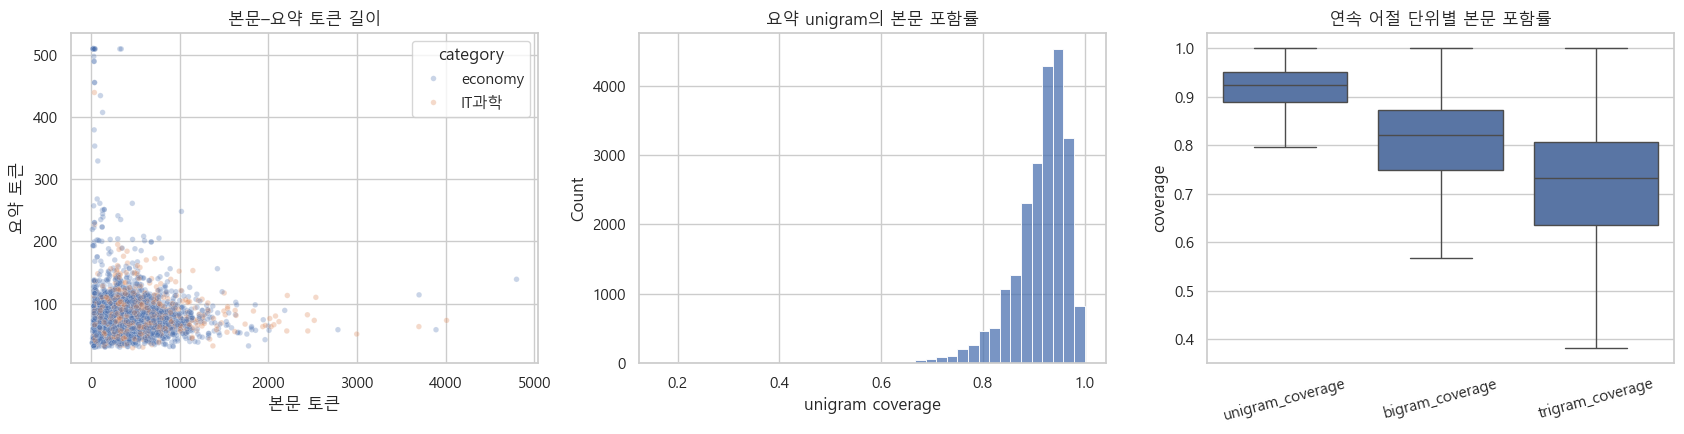

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
pair_sample = train_df.sample(min(5000, len(train_df)), random_state=SEED)
sns.scatterplot(data=pair_sample, x="document_tokens", y="summary_tokens",
                hue="category", alpha=.3, s=16, ax=axes[0])
axes[0].set(title="본문–요약 토큰 길이", xlabel="본문 토큰", ylabel="요약 토큰")
sns.histplot(train_df["unigram_coverage"], bins=40, color="#4c72b0", ax=axes[1])
axes[1].set(title="요약 unigram의 본문 포함률", xlabel="unigram coverage")
coverage_long = train_df[["unigram_coverage", "bigram_coverage", "trigram_coverage"]].melt(
    var_name="단위", value_name="coverage")
sns.boxplot(data=coverage_long, x="단위", y="coverage", showfliers=False, ax=axes[2])
axes[2].set(title="연속 어절 단위별 본문 포함률", xlabel="", ylabel="coverage")
axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGURES / "04_document_summary_pair_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. 숫자·금액·날짜 불일치 후보

요약의 숫자가 본문에 없으면 정답 사실 오류나 다른 기사 요약일 가능성이 있습니다. 쉼표·소수점 표기를 단순 정규화하며, 한글 단위 차이는 완전히 처리하지 못하므로 자동 삭제가 아닌 검토 후보로 사용합니다.

In [21]:
number_pattern = re.compile(r"\d+(?:[,.]\d+)*")

def normalized_numbers(text):
    return {v.replace(",", "").rstrip(".") for v in number_pattern.findall(str(text))}

def unsupported_summary_numbers(document, summary):
    return sorted(normalized_numbers(summary) - normalized_numbers(document))

train_df["unsupported_numbers"] = [
    unsupported_summary_numbers(d, s)
    for d, s in zip(train_df["document"], train_df["summary"])
]
train_df["number_mismatch_candidate"] = train_df["unsupported_numbers"].str.len().gt(0)
number_mismatch_summary_df = (
    train_df.groupby("category")["number_mismatch_candidate"].agg(["sum", "count", "mean"])
    .rename(columns={"sum": "후보 수", "count": "전체 수", "mean": "후보 비율(%)"})
)
number_mismatch_summary_df["후보 비율(%)"] *= 100
display(number_mismatch_summary_df.round(2))

number_mismatch_examples_df = train_df.loc[
    train_df["number_mismatch_candidate"],
    ["date", "category", "press", "title", "document", "summary",
     "unsupported_numbers", "link"]
].copy()
display(number_mismatch_examples_df.head(10))

,후보 수,전체 수,후보 비율(%)
category,,,
IT과학,73,5106,1.43
economy,296,17088,1.73


,date,category,press,title,document,summary,unsupported_numbers,link
43,2022-07-05 18:18:04,economy,파이낸셜뉴스,근로복지공단 부산의원 개원…산재 맞춤재활서비스,근로복지공단은 부산·경상권의 산재노동자들이 보다 가까운 곳에서 전문재활서비스를 받을 수 있도록 부산진구 범천동에 근로복지공단 부산의원 사진 을 설치하고 5일 개원식을 개최했...,근로복지공단은 5일 부산진구 범천동에 근로복지공단 부산의원 사진 을 설치하고 5일 개원식을 개최했다고 밝혔으며 근로복지공단 부산의원 은 신체 회복을 통한 직업 및 사회복귀 ...,[2],https://n.news.naver.com/mnews/article/014/0004862782?sid=101
61,2022-07-06 18:10:04,economy,파이낸셜뉴스,코웨이 취약계층 주거 실내환경 진단해준다,환경부 등과 환경성질환 예방협약 지난 5일 한두원 코웨이 AirCare필터개발팀장 유제철 환경부 차관 이우원 한국환경산업기술원장 직무대행 왼쪽부터 이 기념촬영을 하고 있다....,68년부터 5년 연속 환경성질환 예방사업에 동참하고 있는 코웨이가 취약계층의 실내환경 유해인자를 진단하고 주거시설을 개선하는 사업을 진행하기 위해 6일 환경부 및 한국환경산...,[68],https://n.news.naver.com/mnews/article/014/0004863400?sid=101
92,2022-07-03 21:57:08,economy,KBS,충북 인적자원개발위 청년 구직자 디지털 교육 지원,KBS 청주 충북 인적자원개발위원회가 20 30대 청년 구직자의 디지털 실무 능력을 높이기 위한 교육을 진행합니다. 교육 내용은 인공지능을 활용한 소프트웨어 개발과 빅데이터...,KBS 청주 충북 인적자원개발위원회가 2030세대 구직자의 디지털 실무 능력을 향상시키기 위해 인공지능을 활용한 소프트웨어 개발과 빅데이터 응용으로 한국직업개발원과 한국 I...,[2030],https://n.news.naver.com/mnews/article/056/0011295143?sid=101
253,2022-07-03 17:58:03,IT과학,파이낸셜뉴스,MZ세대 공략 위해… 침체장에도 식지 않는 명품들의 블록체인 사랑,구찌·브라이틀링·페레가모·불가리 가상자산 결제 허용·NFT 발행 최근 가상자산 시장 침체에도 불구하고 구찌나 페라가모 불가리 위블로 브라이틀링 등 명품 브랜드들이 속속 가상...,20 가상자산 시장이 2030 젊은층이 주도하고 있는 가운데 이탈리아 명품 브랜드 구찌 GUCCI가 슈퍼래어 SuperRare 의 가상자산 RARE를 약 3236만5000원...,[20],https://n.news.naver.com/mnews/article/014/0004861308?sid=105
293,2022-07-03 13:10:37,economy,뉴스1,무더위에 냉방 용품 찾는 시민들,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,[7],https://n.news.naver.com/mnews/article/421/0006193841?sid=101
315,2022-07-08 13:14:01,IT과학,동아일보,김 소장의 ‘핏FIT’ 고인의 모습과 고인의 목소리 당신의 추억 방법은,시대의 흐름은 너무나도 빠르게 우리가 상상하던 미래의 모습을 향해 달려가고 있습니다. 때로는 그 속도의 차이가 분야마다 너무 커서 어떤 장단에 맞추어 살아야 할지 고민되고 ...,201 2022년 6월 23일 현지시간 아마존이 미국 라스베이거스에서 개최된 리 마스 re MARS 컨퍼런스에서 AI 음성인식 서비스 ‘알렉사 Alexa ’를 통해 생을 떠...,[201],https://n.news.naver.com/mnews/article/020/0003438915?sid=105
338,2022-07-06 18:15:01,IT과학,한국경제,허준이 교수 고교때부터 수학 집중…사실 수포자는 아니었죠,수학계 노벨상 필즈상 받은 허준이 교수 기자 간담회 순수 수학 강의 듣고 수학에 푹 아직도 헤어나질 못하고 있어 아내 수상 소식에 될 줄 알았어 제2 3 필즈상 수상자 나오...,허준이 한국고등과학원 석학교수 미국 프린스턴대 교수·39 는 6일 서울 역삼동 한국과학기술회관에서 열린 기자간담회에 온라인으로 참석해 ‘수학계의 노벨상’으로 알려진 필즈상 ...,[23],https://n.news.naver.com/mnews/article/015/0004721217?sid=105
393,2022-07-01 23:35:34,economy,머니투데이,현대차 노조 71.8% 파업 찬성...4년만에 파업 벌어질까,서울 뉴시스 김진아 기자 전국금속노동조합 현대차그룹사 노조원들이 26일 오전 서울 서초구 현대기아자동차 본사 앞에서 ‘현대기아그룹사 차별적 가이드라인 분쇄 격려금 동일지급 ...,20차그룹사 노조원들이 26일 오전 서울 서초구 현대기아자동차 본사 앞에서 ‘현대기아그룹사 차별적 가이드라인 분쇄 격려금 동일지급 쟁취 그룹사 공동투쟁 선포 기자회견’을 하...,[20],https://n.news.naver.com/mnews/article/008/0004765955?sid=101
461,2022-07-04 07:55:02,IT과학,스포츠조선,올 상반기 게임사 주가 반토막 속출한 이유는,2022년 상반기 게임사들의 주가는 직격탄 을 맞았다. 코로나19 엔데믹 전환 이후 글로벌 긴축과 경기 침체 우려 우크라이나 전쟁발 급격한 인플레이션 등 엄청난 위기 속에서...,202년 상반기 게임사들의 주가는 코로나19 엔데믹 전환 이후 글로벌 긴축과 경기 침체 우려 우크라이나 전쟁발 급격한 인플레이션 등 엄청난 위기 속에서 다른 나라에 비해 코...,[202],https://n.news.naver.com/mnews/article/076/0003888487?sid=105
463,2022-07-09 07:30:00,IT과학,뉴시스,내달 3일 달로 떠나는 韓 다누리호…맡겨진 임무는,기사내용 요약 미국 발사장로 이송 완료 후 발사 준비 중 내달 3일 스페이스X 팰콘9로 우주行…세계 7번째 달 탐사국 등극 기대↑ 12월 달 상공 100Km 임무궤도 안착 ...,859년 러시아 구 소련가 세계 최초로 달에 무인 우주선을 보냈고 1969년 미국의 닐 암스트롱이 인류 최초로 달을 밟을 때만 해도 세계 최빈국이었던 우리나라가 50 60여...,[859],https://n.news.naver.com/mnews/article/003/0011294695?sid=105


## 15. 기사 앞부분 편향

정답 요약 어절이 본문의 앞 10%, 25%, 50%와 전체에서 얼마나 발견되는지 비교합니다. 앞부분 포함률은 Lead 베이스라인과 긴 본문 자르기 방식의 근거가 됩니다.

,본문 범위,평균 coverage,중앙값 coverage
0,앞 10%,0.246,0.211
1,앞 25%,0.532,0.524
2,앞 50%,0.737,0.822
3,앞 100%,0.912,0.925


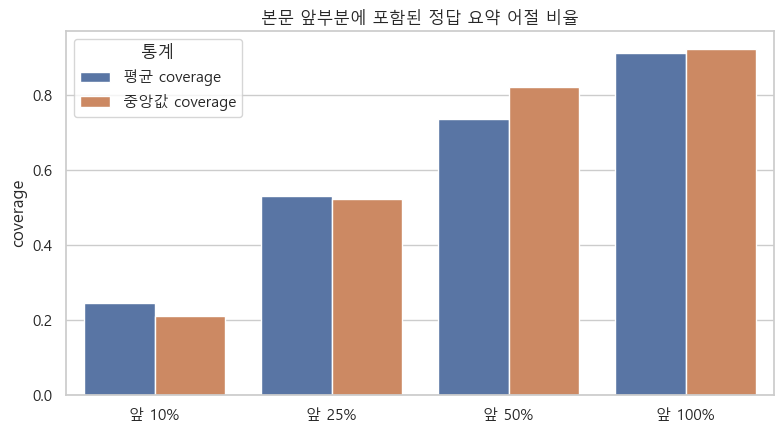

In [22]:
def prefix_word_coverage(document, summary, fraction):
    document_words = normalized_words(document)
    summary_words = normalized_words(summary)
    if not document_words or not summary_words:
        return np.nan
    size = max(1, int(np.ceil(len(document_words) * fraction)))
    prefix = set(document_words[:size])
    return sum(word in prefix for word in summary_words) / len(summary_words)

lead_columns = {}
for fraction in [.10, .25, .50, 1.00]:
    column = f"prefix_{int(fraction*100)}_coverage"
    train_df[column] = [
        prefix_word_coverage(d, s, fraction)
        for d, s in zip(train_df["document"], train_df["summary"])
    ]
    lead_columns[f"앞 {int(fraction*100)}%"] = column

lead_bias_summary_df = pd.DataFrame({
    "본문 범위": list(lead_columns),
    "평균 coverage": [train_df[c].mean() for c in lead_columns.values()],
    "중앙값 coverage": [train_df[c].median() for c in lead_columns.values()],
})
display(lead_bias_summary_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=lead_bias_summary_df.melt(
    id_vars="본문 범위", var_name="통계", value_name="coverage"),
    x="본문 범위", y="coverage", hue="통계", ax=ax)
ax.set(title="본문 앞부분에 포함된 정답 요약 어절 비율", xlabel="", ylabel="coverage")
plt.tight_layout()
plt.savefig(FIGURES / "05_lead_bias.png", dpi=160, bbox_inches="tight")
plt.show()

## 16. TF-IDF 기반 유사 기사 후보

수업에서 배운 TF-IDF로 제목의 unigram·bigram 벡터를 만들고 가까운 제목을 찾습니다. 코사인 유사도 0.8 이상은 같은 사건 후보이며, 실제 그룹 확정 전 사람이 확인해야 합니다.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

similarity_source_df = all_df[["split", "date", "category", "press", "title", "link"]].reset_index(drop=True)
title_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b", ngram_range=(1, 2),
    min_df=2, max_features=50_000, sublinear_tf=True)
title_matrix = title_vectorizer.fit_transform(similarity_source_df["title"].fillna(""))
neighbors = NearestNeighbors(n_neighbors=4, metric="cosine", algorithm="brute", n_jobs=-1)
distances, indices = neighbors.fit(title_matrix).kneighbors(title_matrix)

pairs = {}
for left_index, (row_distances, row_indices) in enumerate(zip(distances, indices)):
    for distance, right_index in zip(row_distances[1:], row_indices[1:]):
        similarity = 1 - float(distance)
        if similarity >= .80 and left_index != right_index:
            pair = tuple(sorted((left_index, int(right_index))))
            pairs[pair] = max(pairs.get(pair, 0), similarity)

similar_rows = []
for (li, ri), similarity in pairs.items():
    left, right = similarity_source_df.iloc[li], similarity_source_df.iloc[ri]
    if left["link"] == right["link"]:
        continue
    similar_rows.append({
        "similarity": similarity, "left_index": li, "right_index": ri,
        "left_split": left["split"], "right_split": right["split"],
        "cross_split": left["split"] != right["split"],
        "left_title": left["title"], "right_title": right["title"],
        "left_press": left["press"], "right_press": right["press"],
        "left_link": left["link"], "right_link": right["link"],
    })

similar_title_candidates_df = pd.DataFrame(similar_rows).sort_values(
    "similarity", ascending=False).reset_index(drop=True)
print("유사 제목 후보 쌍:", f"{len(similar_title_candidates_df):,}")
print("분할 사이 후보 쌍:", f"{similar_title_candidates_df['cross_split'].sum():,}")
display(similar_title_candidates_df.tail())

유사 제목 후보 쌍: 7,769
분할 사이 후보 쌍: 2,536


,similarity,left_index,right_index,left_split,right_split,cross_split,left_title,right_title,left_press,right_press,left_link,right_link
7764,0.800128,9196,24415,train,validation,True,이마트24 타이포그래픽 디자인을 강조한 ‘아임e 스낵’ 판매,이마트24 타이포그래픽 강조한 아임e 스낵 출시,데일리안,뉴시스,https://n.news.naver.com/mnews/article/119/0002618157?sid=101,https://n.news.naver.com/mnews/article/003/0011285406?sid=101
7765,0.800039,14093,20364,train,train,False,드론인재양성 2022서울드론 아카데미 개소,메타버스 아카데미 개소,한국경제TV,전자신문,https://n.news.naver.com/mnews/article/215/0001040612?sid=101,https://n.news.naver.com/mnews/article/030/0003028275?sid=105
7766,0.800030,3741,17821,train,train,False,우리은행 마스크 업사이클링 작품 전시회 개최,우리은행 6일까지 마스크 업사이클링 작품 전시회,데일리안,머니투데이,https://n.news.naver.com/mnews/article/119/0002617389?sid=101,https://n.news.naver.com/mnews/article/008/0004765821?sid=101
7767,0.800030,17821,21231,train,train,False,우리은행 6일까지 마스크 업사이클링 작품 전시회,우리은행 마스크 업사이클링 작품 전시회 개최,머니투데이,연합뉴스,https://n.news.naver.com/mnews/article/008/0004765821?sid=101,https://n.news.naver.com/mnews/article/001/0013283350?sid=101
7768,0.800030,1551,17821,train,train,False,우리은행 마스크 업사이클링 작품 전시회 개최,우리은행 6일까지 마스크 업사이클링 작품 전시회,뉴시스,머니투데이,https://n.news.naver.com/mnews/article/003/0011279495?sid=101,https://n.news.naver.com/mnews/article/008/0004765821?sid=101


## 17. 언론사 편중과 텍스트 품질

특정 언론사의 과대표집 여부와 URL·이메일·저작권 문구·연속 공백·매우 짧은 기사 빈도를 확인합니다.

split,train,validation,test,total,전체 비율(%)
press,,,,,
연합뉴스,2060,209,260,2529,9.23
뉴스1,1787,202,221,2210,8.07
뉴시스,1662,187,215,2064,7.53
이데일리,1278,159,156,1593,5.81
파이낸셜뉴스,961,123,116,1200,4.38
머니투데이,825,89,101,1015,3.70
한국경제,832,70,107,1009,3.68
아시아경제,815,71,92,978,3.57
서울경제,715,67,80,862,3.15


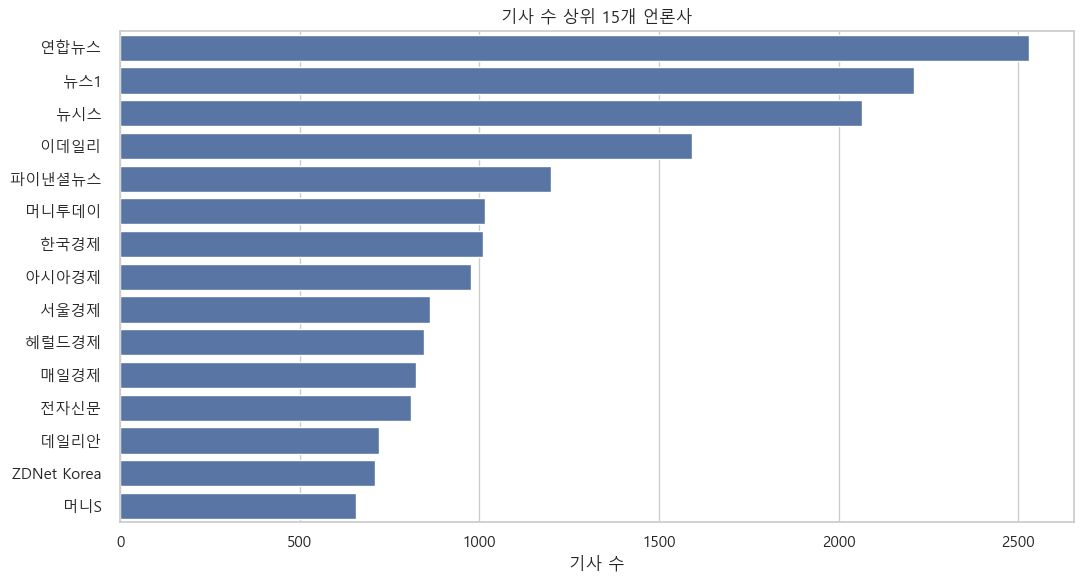

In [24]:
press_counts_df = (all_df.groupby(["press", "split"], observed=True).size()
                   .unstack(fill_value=0).reindex(columns=split_order, fill_value=0))
press_counts_df["total"] = press_counts_df.sum(axis=1)
press_counts_df["전체 비율(%)"] = press_counts_df["total"] / len(all_df) * 100
press_counts_df = press_counts_df.sort_values("total", ascending=False)
display(press_counts_df.head(20).round(2))

fig, ax = plt.subplots(figsize=(11, 6))
top_press = press_counts_df.head(15).reset_index()
sns.barplot(data=top_press, y="press", x="total", color="#4c72b0", ax=ax)
ax.set(title="기사 수 상위 15개 언론사", xlabel="기사 수", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / "06_press_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

In [25]:
quality_patterns = {
    "URL 포함": re.compile(r"https?://|www\.", re.I),
    "이메일 포함": re.compile(r"[\w.+-]+@[\w.-]+\.\w+", re.I),
    "저작권/재배포 문구": re.compile(r"무단전재|재배포\s*금지|저작권자|copyright", re.I),
    "연속 공백": re.compile(r"\s{2,}"),
    "기자 표현": re.compile(r"[가-힣]{2,4}\s*기자"),
}
text_quality_rows = []
for split in split_order:
    frame = frames[split]
    documents = frame["document"].fillna("").astype(str)
    for name, pattern in quality_patterns.items():
        mask = documents.str.contains(pattern, regex=True)
        text_quality_rows.append({"split": split, "패턴": name,
                                  "건수": int(mask.sum()), "비율(%)": mask.mean()*100})
    short_mask = frame["document_words"].lt(30)
    text_quality_rows.append({"split": split, "패턴": "30어절 미만 본문",
                              "건수": int(short_mask.sum()), "비율(%)": short_mask.mean()*100})
text_quality_summary_df = pd.DataFrame(text_quality_rows)
display(text_quality_summary_df.pivot(index="패턴", columns="split", values="건수")
        .reindex(columns=split_order))

split,train,validation,test
패턴,,,
30어절 미만 본문,1292,140,142
URL 포함,62,6,15
기자 표현,9259,1035,1144
연속 공백,0,0,0
이메일 포함,0,0,0
저작권/재배포 문구,25,1,0


## 18. 극단값과 의심 쌍 직접 확인

긴·짧은 본문, 긴 요약, 낮은 내용 일치도, 반복 요약과 숫자 불일치 사례를 원문·정답 쌍으로 저장합니다.

In [26]:
review_sets = []
def add_review_set(label, frame):
    temp = frame.copy()
    temp.insert(0, "review_reason", label)
    review_sets.append(temp)

base_review = ["date", "category", "press", "title", "document", "summary", "link",
               "document_tokens", "summary_tokens", "char_compression_ratio"]
add_review_set("가장 긴 본문", train_df.nlargest(5, "document_tokens")[base_review])
add_review_set("가장 짧은 본문", train_df.nsmallest(5, "document_tokens")[base_review])
add_review_set("가장 긴 요약", train_df.nlargest(5, "summary_tokens")[base_review])
add_review_set("가장 낮은 unigram coverage",
               train_df.nsmallest(10, "unigram_coverage")[
                   base_review + ["unigram_coverage", "bigram_coverage", "trigram_coverage"]])
add_review_set("반복 요약", train_df.loc[train_df["repeat_4gram"]]
               .sort_values("summary_tokens", ascending=False).head(10)[base_review + ["repeat_4gram"]])
add_review_set("숫자 불일치 후보", train_df.loc[train_df["number_mismatch_candidate"]]
               .head(10)[base_review + ["unsupported_numbers"]])
extreme_pair_examples_df = pd.concat(review_sets, ignore_index=True, sort=False)
display(extreme_pair_examples_df[["review_reason", "title", "document_tokens",
    "summary_tokens", "char_compression_ratio", "unigram_coverage",
    "unsupported_numbers"]].head(30))

,review_reason,title,document_tokens,summary_tokens,char_compression_ratio,unigram_coverage,unsupported_numbers
0,가장 긴 본문,성공예감 실전 귀농 꿀팁 핸드폰은 제2의 농기구 – 표성미 작가『나는 시골에서 비즈니스한다』,6781,86,0.012904,NaN,NaN
1,가장 긴 본문,성공예감 패션 브랜드에서 ‘옷 사지 마세요’ 하는 이유 낫아워스 박진영·신하나 대표,6727,47,0.006868,NaN,NaN
2,가장 긴 본문,성공예감 30% 빠진 코스피 더 빠지면 금융 위기 국면으로 김학균 신영증권 리서치센터장,6240,119,0.019010,NaN,NaN
3,가장 긴 본문,생활경제뉴스 아이허브 네이버페이 결제 서비스 시작 外,4833,68,0.017354,NaN,NaN
4,가장 긴 본문,내년 최저임금 5%↑ 9620원...노사 모두 반발,4798,139,0.026053,NaN,NaN
5,가장 짧은 본문,속보6월 소비자물가 6.0% 상승…1998년 11월 이후 최고,11,79,6.758621,NaN,NaN
6,가장 짧은 본문,재송4일 장마감 후 주요 종목 뉴스,12,509,28.531250,NaN,NaN
7,가장 짧은 본문,5일 장마감 후 주요 종목 뉴스,12,60,4.937500,NaN,NaN
8,가장 짧은 본문,4일 장마감 후 주요 종목 뉴스,12,509,28.531250,NaN,NaN
9,가장 짧은 본문,6일 장마감 후 주요 뉴스,12,40,3.406250,NaN,NaN


## 19. 전처리 판단표

자동 탐지 결과와 실제 처리를 분리합니다. 이번 단계에서는 후보만 기록하고, 사례 검토와 비교 실험 전에 삭제하지 않습니다.

In [27]:
decision_table_df = pd.DataFrame([
    ["결측치/빈 문자열", int(quality_df["missing"].sum()+quality_df["empty"].sum()),
     "없음", "발견 시 해당 행 검토"],
    ["분할 사이 동일 본문", len(cross_document_examples_df),
     "유지", "원본 분할과 그룹 분할 비교"],
    ["TF-IDF 유사 제목 쌍(0.8 이상)", len(similar_title_candidates_df),
     "유지", "사례 확인 후 사건 그룹 후보로 사용"],
    ["반복 요약", int(train_df["repeat_4gram"].sum()),
     "유지", "사람 검토 후 노이즈 제거 비교"],
    ["숫자 불일치 후보", int(train_df["number_mismatch_candidate"].sum()),
     "유지", "표기 차이를 고려해 사람 검토"],
    ["낮은 본문–요약 일치도", int(train_df["unigram_coverage"].lt(.30).sum()),
     "유지", "다른 기사 요약 여부 확인"],
    ["512토큰 초과 본문(train)", int(train_df["document_tokens"].gt(512).sum()),
     "삭제하지 않음", "512와 1024 입력 길이 비교"],
], columns=["문제", "탐지 건수", "현재 처리", "다음 계획"])
display(decision_table_df)

,문제,탐지 건수,현재 처리,다음 계획
0,결측치/빈 문자열,0,없음,발견 시 해당 행 검토
1,분할 사이 동일 본문,612,유지,원본 분할과 그룹 분할 비교
2,TF-IDF 유사 제목 쌍(0.8 이상),7769,유지,사례 확인 후 사건 그룹 후보로 사용
3,반복 요약,1121,유지,사람 검토 후 노이즈 제거 비교
4,숫자 불일치 후보,369,유지,표기 차이를 고려해 사람 검토
5,낮은 본문–요약 일치도,6,유지,다른 기사 요약 여부 확인
6,512토큰 초과 본문(train),6108,삭제하지 않음,512와 1024 입력 길이 비교


## 20. 추가 분석 결과 저장

입력–정답 쌍, 숫자 불일치, 앞부분 편향, 유사 기사, 언론사와 텍스트 품질 결과를 CSV·JSON으로 저장합니다.

In [28]:
pair_feature_columns = [
    "date", "category", "press", "title", "link", "document_chars", "summary_chars",
    "document_tokens", "summary_tokens", "char_compression_ratio",
    "unigram_coverage", "bigram_coverage", "trigram_coverage", "novel_unigram_ratio",
    "prefix_10_coverage", "prefix_25_coverage", "prefix_50_coverage",
    "prefix_100_coverage", "number_mismatch_candidate", "unsupported_numbers"]
pair_features_df = train_df[pair_feature_columns].copy()
pair_features_df["unsupported_numbers"] = pair_features_df["unsupported_numbers"].map("|".join)

pair_quality_summary_df.to_csv(RESULTS/"pair_quality_summary.csv", encoding="utf-8-sig")
pair_features_df.to_csv(RESULTS/"train_pair_features.csv", index=False, encoding="utf-8-sig")
number_mismatch_summary_df.to_csv(RESULTS/"number_mismatch_summary.csv", encoding="utf-8-sig")
number_mismatch_examples_df.assign(
    unsupported_numbers=number_mismatch_examples_df["unsupported_numbers"].map("|".join)
).to_csv(RESULTS/"number_mismatch_candidates.csv", index=False, encoding="utf-8-sig")
lead_bias_summary_df.to_csv(RESULTS/"lead_bias_summary.csv", index=False, encoding="utf-8-sig")
similar_title_candidates_df.to_csv(RESULTS/"similar_title_candidates.csv", index=False, encoding="utf-8-sig")
press_counts_df.to_csv(RESULTS/"press_distribution.csv", encoding="utf-8-sig")
text_quality_summary_df.to_csv(RESULTS/"text_quality_summary.csv", index=False, encoding="utf-8-sig")
extreme_pair_examples_df.to_csv(RESULTS/"extreme_pair_examples.csv", index=False, encoding="utf-8-sig")
decision_table_df.to_csv(RESULTS/"preprocessing_decision_table.csv", index=False, encoding="utf-8-sig")

pair_run_summary = {
    "pair_quality": pair_quality_summary_df.reset_index().rename(
        columns={"index":"metric"}).to_dict(orient="records"),
    "number_mismatch_candidates": int(train_df["number_mismatch_candidate"].sum()),
    "lead_bias": lead_bias_summary_df.to_dict(orient="records"),
    "similar_title_pairs_threshold_0_8": len(similar_title_candidates_df),
    "cross_split_similar_title_pairs": int(similar_title_candidates_df["cross_split"].sum()),
    "preprocessing_decisions": decision_table_df.to_dict(orient="records"),
    "warning": "자동 규칙은 검토 후보이며 오류 확정이나 자동 삭제 기준이 아님",
}
(RESULTS/"pair_analysis_summary.json").write_text(
    json.dumps(pair_run_summary, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("추가 분석 저장 완료:", RESULTS)
print("그래프 수:", len(list(FIGURES.glob("*.png"))))
print("CSV 수:", len(list(RESULTS.glob("*.csv"))))

추가 분석 저장 완료: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda
그래프 수: 7
CSV 수: 22


## 21. EDA 결론

- train 요약 어절의 평균 91.2%가 본문에도 등장하고, bigram은 79.9%, trigram은 70.8%가 그대로 등장했습니다. 정답 요약은 생성형이지만 본문 표현을 많이 유지하는 편입니다.
- 요약 어절의 평균 25%가 본문 앞 10%, 53%가 앞 25%, 74%가 앞 50% 안에서 발견됐습니다. Lead 베이스라인과 앞부분 입력 전략을 비교할 근거가 있습니다.
- 숫자 불일치 후보 369건, 반복 요약 후보 1,121건을 찾았습니다. 표기 차이와 정상 반복이 포함될 수 있어 사람이 사례를 확인한 뒤 노이즈 제거 전후를 비교합니다.
- TF-IDF 제목 유사도 0.8 이상 후보는 7,769쌍이며 그중 2,536쌍이 서로 다른 분할에 걸쳐 있습니다. 이는 같은 사건의 확정 개수가 아니라 그룹 분할을 위한 검토 후보입니다.
- train 본문의 27.52%가 512토큰을 초과하고 약 4.14%가 1024토큰을 초과합니다. 이후 512와 1024 입력 길이를 validation 성능·학습 시간·GPU 메모리로 비교합니다.
- 이번 단계에서는 원본 데이터를 삭제하거나 수정하지 않았습니다. 자동 규칙은 검토 대상을 좁히는 용도입니다.

## 22. 제목·본문·요약의 중복 관계

단일 컬럼의 중복 개수에서 한 단계 더 나아가 다음 관계를 정확한 문자열 기준으로 구분합니다.

1. 같은 본문인데 정답 요약이 다른 경우
2. 서로 다른 본문인데 정답 요약이 같은 경우
3. 제목은 같지만 본문과 요약이 모두 다른 경우
4. 제목은 같고 요약도 같지만 본문만 다른 경우

각 그룹이 train·validation·test 중 둘 이상에 걸쳐 있는지도 확인합니다. 띄어쓰기나 일부 문구가 다른 유사 중복은 이 표에 포함되지 않으며 TF-IDF 후보 분석에서 별도로 다룹니다.

In [29]:
relation_source_df = all_df[[
    "split", "date", "category", "press", "title",
    "document", "summary", "link"
]].reset_index(drop=True).copy()

def aggregate_relation(key):
    return (
        relation_source_df.groupby(key, dropna=False)
        .agg(
            rows=("link", "size"),
            split_count=("split", "nunique"),
            unique_documents=("document", "nunique"),
            unique_summaries=("summary", "nunique"),
            unique_titles=("title", "nunique"),
            unique_links=("link", "nunique"),
        )
        .reset_index()
    )

document_groups = aggregate_relation("document")
summary_groups = aggregate_relation("summary")
title_groups = aggregate_relation("title")

relation_definitions = {
    "같은 본문-다른 요약": (
        "document",
        document_groups.loc[document_groups["unique_summaries"].gt(1)].copy(),
    ),
    "다른 본문-같은 요약": (
        "summary",
        summary_groups.loc[summary_groups["unique_documents"].gt(1)].copy(),
    ),
    "같은 제목-다른 본문·요약": (
        "title",
        title_groups.loc[
            title_groups["unique_documents"].gt(1)
            & title_groups["unique_summaries"].gt(1)
        ].copy(),
    ),
    "같은 제목·요약-다른 본문": (
        "title",
        title_groups.loc[
            title_groups["unique_documents"].gt(1)
            & title_groups["unique_summaries"].eq(1)
        ].copy(),
    ),
}

relationship_summary_rows = []
for relation, (key, groups) in relation_definitions.items():
    relationship_summary_rows.append({
        "관계": relation,
        "그룹 수": len(groups),
        "포함 행 수": int(groups["rows"].sum()),
        "분할 간 그룹 수": int(groups["split_count"].gt(1).sum()),
        "그룹 기준": key,
    })

duplicate_relationship_summary_df = pd.DataFrame(relationship_summary_rows)
display(duplicate_relationship_summary_df)

,관계,그룹 수,포함 행 수,분할 간 그룹 수,그룹 기준
0,같은 본문-다른 요약,0,0,0,document
1,다른 본문-같은 요약,21,100,9,summary
2,같은 제목-다른 본문·요약,726,1942,295,title
3,같은 제목·요약-다른 본문,6,18,1,title


In [30]:
def relation_memberships(relation, key, groups):
    if groups.empty:
        return pd.DataFrame()
    selected = groups[[key]].copy()
    members = relation_source_df.merge(selected, on=key, how="inner")
    members.insert(0, "관계", relation)
    members.insert(
        1,
        "group_id",
        members[key].astype(str).map(
            lambda value: hashlib.sha256(value.encode("utf-8")).hexdigest()
        ),
    )
    members.insert(
        2,
        "group_value_preview",
        members[key].astype(str).str.slice(0, 200),
    )
    return members

relationship_membership_frames = [
    relation_memberships(relation, key, groups)
    for relation, (key, groups) in relation_definitions.items()
]
relationship_membership_frames = [
    frame for frame in relationship_membership_frames if not frame.empty
]
duplicate_relationship_rows_df = pd.concat(
    relationship_membership_frames, ignore_index=True, sort=False
)

example_columns = [
    "관계", "group_id", "split", "title", "document", "summary", "link"
]
for relation in duplicate_relationship_summary_df["관계"]:
    examples = duplicate_relationship_rows_df.loc[
        duplicate_relationship_rows_df["관계"].eq(relation), example_columns
    ]
    print(f"\n[{relation}]")
    if examples.empty:
        print("해당 사례 없음")
    else:
        first_group = examples["group_id"].iloc[0]
        display(examples.loc[examples["group_id"].eq(first_group)])


[같은 본문-다른 요약]
해당 사례 없음

[다른 본문-같은 요약]


,관계,group_id,split,title,document,summary,link
0,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,개문냉방 영업 속출…전력난 어쩌나,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285584?sid=101
1,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,개문냉방 영업 속출…전력난 어쩌나,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285548?sid=101
22,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,전력난에도 폭염에 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285533?sid=101
41,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,전력난에도 폭염에 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285530?sid=101
43,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,전력난에도 폭염에 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285532?sid=101
48,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,줄줄이 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285587?sid=101
72,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,개문냉방 영업 속출…전력난 어쩌나,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285541?sid=101



[같은 제목-다른 본문·요약]


,관계,group_id,split,title,document,summary,link
100,같은 제목-다른 본문·요약,a589d64b60354c9d0e1a545c5d3344fe3a9ee049528ef527845ddc510aaf9793,train,에디슨이노 이승훈 제이스페이스 대표 사내이사 선임,기사내용 요약 우주발사체 사업 본격화 서울 뉴시스 김경택 기자 에디슨이노가 우주발사체 사업에 본격 진출한다고 1일 밝혔다. 에디슨이노는 전날 임시주주총회를 통해 사명을 이노...,에디슨이노는 1일 임시주주총회를 통해 사명을 이노시스 로 변경하고 이승훈 제이스페이스홀딩스 대표이사를 사내이사로 선임하고 위성체 발사와 우주선 위성시스템 등 항공 우주 분야...,https://n.news.naver.com/mnews/article/003/0011279060?sid=101
1390,같은 제목-다른 본문·요약,a589d64b60354c9d0e1a545c5d3344fe3a9ee049528ef527845ddc510aaf9793,train,에디슨이노 이승훈 제이스페이스 대표 사내이사 선임,우주발사체 사업 본격화 에디슨이노 CI 파이낸셜뉴스 에디슨이노 INNO 는 제이스페이스홀딩스를 통해 우주발사체 사업을 확대한다고 1일 밝혔다. 1일 금융감독원 전자공시시스템...,에 금융감독원 전자공시시스템에 따르면 에디슨이노는 전일 임시 주주총회를 열고 사명을 이노시스 로 변경하고 제이스페이스홀딩스를 통해 우주발사체 사업을 확대한다고 1일 밝혔으며...,https://n.news.naver.com/mnews/article/014/0004860623?sid=101



[같은 제목·요약-다른 본문]


,관계,group_id,split,title,document,summary,link
2042,같은 제목·요약-다른 본문,4e38455c5dc54ee48f1774792634061295114cf01524ac020269ed67d5062d09,train,한·일 재계 3년만에 만나… 무비자 입국제도 부활 인적교류 확대해야,일본의 수출규제 신종 코로나바이러스 감염증 코로나19 유행으로 교류가 끊겼던 한·일 경제단체가 3년 만에 만났다. 한·일 재계는 양국 관계 개선과 무비자 입국제도 부활을 통...,최근 4일 서울 여의도 전경련회관에서 일본 경제단체연합회 게이단렌 과 제29회 한일재계회의가 열려 신종 코로나바이러스감염증 코로나19 여파로 교류가 끊겼던 한·일 경제단체가...,https://n.news.naver.com/mnews/article/025/0003207197?sid=101
2044,같은 제목·요약-다른 본문,4e38455c5dc54ee48f1774792634061295114cf01524ac020269ed67d5062d09,train,한·일 재계 3년만에 만나… 무비자 입국제도 부활 인적교류 확대해야,일본의 수출규제 신종 코로나바이러스 감염증 코로나19 유행으로 교류가 끊겼던 한·일 경제단체가 3년 만에 만났다. 한·일 재계는 양국 관계 개선과 무비자 입국제도 부활을 통...,최근 4일 서울 여의도 전경련회관에서 일본 경제단체연합회 게이단렌 과 제29회 한일재계회의가 열려 신종 코로나바이러스감염증 코로나19 여파로 교류가 끊겼던 한·일 경제단체가...,https://n.news.naver.com/mnews/article/025/0003207104?sid=101


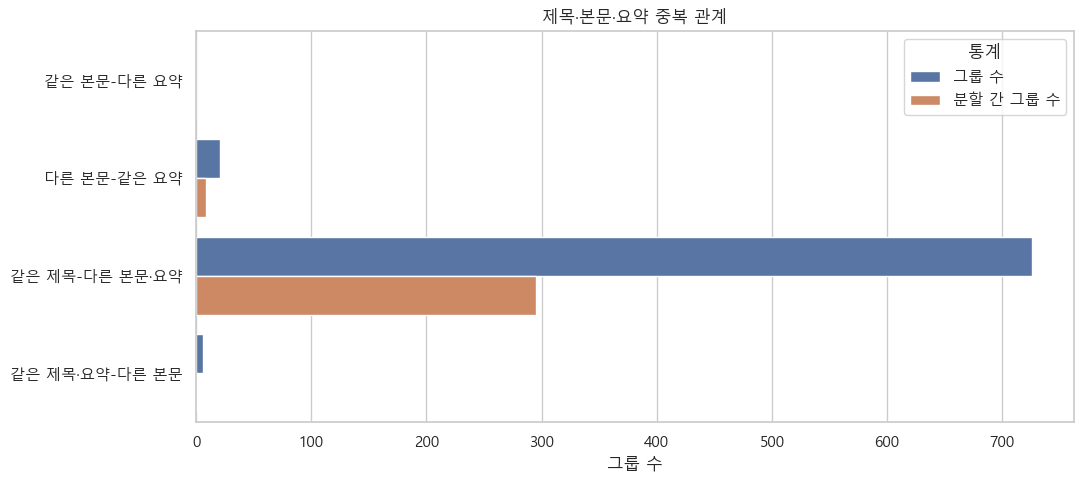

In [31]:
plot_df = duplicate_relationship_summary_df.melt(
    id_vars="관계",
    value_vars=["그룹 수", "분할 간 그룹 수"],
    var_name="통계", value_name="개수",
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, y="관계", x="개수", hue="통계", ax=ax)
ax.set_title("제목·본문·요약 중복 관계")
ax.set_xlabel("그룹 수")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(
    FIGURES / "07_duplicate_relationships.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### 관계 중복의 해석

- 같은 본문에 서로 다른 요약이 붙은 사례가 없다면, 정확히 동일한 본문 중복은 같은 정답을 공유합니다.
- 다른 본문에 같은 요약이 붙은 사례는 사진 연속 기사처럼 정상일 수도 있고 정답 재사용 문제일 수도 있습니다.
- 같은 제목에 서로 다른 본문·요약이 붙은 사례는 동일 사건의 후속 기사, 사진 기사 또는 동일 제목 재사용일 수 있습니다.
- 이 관계가 분할 사이에 걸치면 같은 사건을 학습하고 평가할 가능성이 있으므로 그룹 분할 후보가 됩니다.
- 자동 삭제하지 않고 원문·요약·링크를 함께 검토합니다.

In [32]:
duplicate_relationship_summary_df.to_csv(
    RESULTS / "duplicate_relationship_summary.csv",
    index=False,
    encoding="utf-8-sig",
)
duplicate_relationship_rows_df.to_csv(
    RESULTS / "duplicate_relationship_rows.csv",
    index=False,
    encoding="utf-8-sig",
)

# 기존 판단표에도 관계 중복 결과를 연결합니다.
relation_decisions = duplicate_relationship_summary_df.loc[
    duplicate_relationship_summary_df["그룹 수"].gt(0),
    ["관계", "그룹 수"],
].rename(columns={"관계": "문제", "그룹 수": "탐지 건수"})
relation_decisions["현재 처리"] = "유지"
relation_decisions["다음 계획"] = "사례 확인 후 그룹 분할·노이즈 제거 비교"

decision_table_with_relations_df = pd.concat(
    [decision_table_df, relation_decisions],
    ignore_index=True,
).drop_duplicates(subset=["문제"], keep="last")
decision_table_with_relations_df.to_csv(
    RESULTS / "preprocessing_decision_table.csv",
    index=False,
    encoding="utf-8-sig",
)

print("저장:", RESULTS / "duplicate_relationship_summary.csv")
print("저장:", RESULTS / "duplicate_relationship_rows.csv")
display(decision_table_with_relations_df)

저장: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda\duplicate_relationship_summary.csv
저장: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda\duplicate_relationship_rows.csv


,문제,탐지 건수,현재 처리,다음 계획
0,결측치/빈 문자열,0,없음,발견 시 해당 행 검토
1,분할 사이 동일 본문,612,유지,원본 분할과 그룹 분할 비교
2,TF-IDF 유사 제목 쌍(0.8 이상),7769,유지,사례 확인 후 사건 그룹 후보로 사용
3,반복 요약,1121,유지,사람 검토 후 노이즈 제거 비교
4,숫자 불일치 후보,369,유지,표기 차이를 고려해 사람 검토
5,낮은 본문–요약 일치도,6,유지,다른 기사 요약 여부 확인
6,512토큰 초과 본문(train),6108,삭제하지 않음,512와 1024 입력 길이 비교
7,다른 본문-같은 요약,21,유지,사례 확인 후 그룹 분할·노이즈 제거 비교
8,같은 제목-다른 본문·요약,726,유지,사례 확인 후 그룹 분할·노이즈 제거 비교
9,같은 제목·요약-다른 본문,6,유지,사례 확인 후 그룹 분할·노이즈 제거 비교


## 23. 중복 관계 분석 결론

정확한 문자열 기준으로 **같은 본문–다른 요약은 발견되지 않았습니다.** 반면 다른 본문–같은 요약과 같은 제목–다른 본문·요약 관계가 존재합니다. 특히 서로 다른 분할에 걸친 그룹은 무작위 분할에서 동일 사건이 학습과 평가 양쪽에 들어갈 수 있음을 보여줍니다.

따라서 기본 실험은 제공된 원본 분할을 유지하고, 비교 실험에서는 제목·본문 유사도를 이용해 동일 사건 후보가 한 분할에만 들어가도록 그룹 분할을 구성합니다. 이때 현재 표의 정확 중복과 TF-IDF 유사 후보를 함께 사용하고, test 설정은 최종 평가 전에 고정합니다.